# TFM — Análisis de la severidad de la sintomatología depresiva (ESdE 2023)

Este cuaderno desarrolla la preparación, el análisis exploratorio, la modelización multiclase y la evaluación de los modelos de regresión logística multinomial y Random Forest.

**Fuente:** Microdatos del cuestionario de adultos de la Encuesta de Salud de España 2023 (ESdE 2023).

**Alumno**: Pablo Bilbao Pozo

**Correo**: pbilbaop@student.universidadviu.com

## 1. Inicialización

In [ ]:
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, classification_report,
    confusion_matrix, roc_auc_score
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")

## 2. Carga de los microdatos

Subir el fichero `ESdEadulto_2023.tab`. El separador del fichero es una tabulación.

In [ ]:
uploaded = files.upload()

file_name = next(iter(uploaded))
df_original = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    sep="\t",
    low_memory=False
)

print("Dimensiones:", df_original.shape)
display(df_original.head())
display(df_original.info())

Saving ESdEadulto_2023.tab to ESdEadulto_2023.tab
Dimensiones: (21032, 432)


,CCAA,IDENTHOGAR,NORDENa,SEXOa,EDADa,PROXY_0,PROXY_1,PROXY_2,PROXY_2b,PROXY_4,PROXY_5,PROXY_6,A1a,A1c,A1e,A2a_1,A2a_2,A2a_3,A3,A4,A5,NIVEST,B1,B2,B3_2,B4_2,B5,B6,B7,B8,B9a,B9b,B10,B11,B12,B13a_2,B13b_2,B14a_2,B14b_2,B15,C1,C2,C3a,C3b,C4,C5a_1,C5b_1,C5c_1,C5a_2,C5b_2,...,R2vin_6,R2vin_7,R2vermut,R2vermut_1,R2vermut_2,R2vermut_3,R2vermut_4,R2vermut_5,R2vermut_6,R2vermut_7,R2lic,R2lic_1,R2lic_2,R2lic_3,R2lic_4,R2lic_5,R2lic_6,R2lic_7,R2comb,R2comb_1,R2comb_2,R2comb_3,R2comb_4,R2comb_5,R2comb_6,R2comb_7,R2sidra,R2sidra_1,R2sidra_2,R2sidra_3,R2sidra_4,R2sidra_5,R2sidra_6,R2sidra_7,R3,S1,S2,S3,T1,T2,T3,FACTORADULTO,CLASE_PR,IMC,CMD1,CMD2,CMD3,INDICE_BIENESTAR,SEVERIDAD_DEPRESIVA,CUADROS_DEPRESIVOS
0,16,1,1,1,75,1,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,2,2,NaN,3,1,7,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,241.0,NaN,812.0,1.0,2,1,3,NaN,2,1,1.0,1.0,2,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,4,1,1,2,NaN,NaN,547.893,5,3,0.00,0.0,0.0,84,1,3
1,16,2,1,2,96,2,2.0,2.0,NaN,1.0,62.0,2.0,1,1,1,1,2,2,NaN,3,3,4,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,475.0,NaN,530.0,3.0,4,1,1,3.0,3,1,1.0,1.0,2,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,1,2,2,NaN,NaN,714.313,3,2,0.00,0.0,0.0,24,4,1
2,16,3,1,2,74,1,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,2,2,NaN,3,3,4,2.0,NaN,291.0,970.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,1,3,NaN,3,1,1.0,1.0,2,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,4,1,1,2,NaN,NaN,567.742,6,3,0.00,0.0,0.0,80,1,3
3,16,4,2,2,79,1,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,2,2,NaN,1,2,4,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,141.0,NaN,783.0,1.0,2,1,3,NaN,2,1,1.0,1.0,2,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,1,1,2,NaN,NaN,1433.792,4,2,0.00,0.0,0.0,100,1,3
4,16,5,1,1,70,1,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2,1,2,9.0,1,2,4,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,563.0,NaN,512.0,1.0,2,1,3,NaN,2,1,1.0,1.0,2,NaN,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,4,1,1,2,NaN,NaN,1543.118,5,2,4.29,0.0,10.0,100,1,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21032 entries, 0 to 21031
Columns: 432 entries, CCAA to CUADROS_DEPRESIVOS
dtypes: float64(284), int64(148)
memory usage: 69.3 MB


None

## 3. Inspección inicial

Se comprueban dimensiones, nombres, tipos, duplicados, valores ausentes y existencia de las variables seleccionadas. `FACTORADULTO` se conserva para los análisis descriptivos ponderados; no se incorpora como predictor.

In [ ]:
print("Número de filas:", df_original.shape[0])
print("Número de columnas:", df_original.shape[1])
print("Filas duplicadas completas:", df_original.duplicated().sum())

display(
    pd.DataFrame({
        "tipo": df_original.dtypes.astype(str),
        "n_valores_distintos": df_original.nunique(dropna=True),
        "n_ausentes": df_original.isna().sum(),
        "porcentaje_ausentes": (df_original.isna().mean() * 100).round(2)
    }).sort_values("porcentaje_ausentes", ascending=False)
)

assert "SEVERIDAD_DEPRESIVA" in df_original.columns
assert "FACTORADULTO" in df_original.columns

Número de filas: 21032
Número de columnas: 432
Filas duplicadas completas: 0


,tipo,n_valores_distintos,n_ausentes,porcentaje_ausentes
K3_17b,float64,2,20962,99.67
B9b,float64,6,20949,99.61
K3_16b,float64,2,20929,99.51
K3_21b,float64,3,20851,99.14
P3,float64,7,20849,99.13
...,...,...,...,...
A2a_2,int64,2,0,0.00
A2a_3,int64,1,0,0.00
A4,int64,4,0,0.00
A5,int64,6,0,0.00


## 4. Definición de variables

La selección parte del Apéndice A del TFM. Se excluyen del modelo principal `B6`, `B8` y `B11` porque el cuestionario las dirige a subpoblaciones concretas y presentan una proporción elevada de ausencias estructurales. Se mantienen como variables de interés exploratorio.

Para las variables de enfermedades `C5b`, la pregunta solo se formula si la respuesta previa `C5a` indica que la persona ha padecido alguna vez esa enfermedad. Si `C5a=2` (no la ha padecido), se puede derivar `C5b=2` (no la ha padecido en los últimos 12 meses). Si `C5a=9`, la respuesta se conserva como desconocida.

**Importante:** `R1=9` es una respuesta válida («nunca o solamente unos sorbos»); el código de no sabe/no contesta es `99`. Por ello, no se sustituyen indiscriminadamente todos los códigos 9.

In [ ]:
target = "SEVERIDAD_DEPRESIVA"
weight_col = "FACTORADULTO"

numeric_features = ["EDADa"]

categorical_features = [
    "SEXOa", "NIVEST", "A4", "A5", "A1a", "CCAA", "CLASE_PR",
    "C1", "C2", "C3a", "C4", "O2", "IMC", "R1", "S1", "S2", "S3"
]

disease_ids = [1, 2, 6, 7, 8, 12]
for disease_id in disease_ids:
    categorical_features.append(f"C5b_{disease_id}")

exploratory_only = ["B6", "B8", "B11"]

required = [target, weight_col] + numeric_features + categorical_features
missing_columns = [c for c in required if c not in df_original.columns]
if missing_columns:
    raise ValueError(f"Faltan variables en el fichero: {missing_columns}")

print("Variables numéricas:", numeric_features)
print("Variables categóricas:", categorical_features)
print("Variables reservadas para análisis exploratorio:", exploratory_only)

Variables numéricas: ['EDADa']
Variables categóricas: ['SEXOa', 'NIVEST', 'A4', 'A5', 'A1a', 'CCAA', 'CLASE_PR', 'C1', 'C2', 'C3a', 'C4', 'O2', 'IMC', 'R1', 'S1', 'S2', 'S3', 'C5b_1', 'C5b_2', 'C5b_6', 'C5b_7', 'C5b_8', 'C5b_12']
Variables reservadas para análisis exploratorio: ['B6', 'B8', 'B11']


## 5. Tratamiento de la variable objetivo y de los códigos especiales

Se excluye el código 9 de la variable objetivo, que corresponde a respuesta no válida/no informada en las preguntas de salud mental del cuestionario. Las categorías válidas se mantienen separadas (1–5), sin agrupaciones.

In [ ]:
df = df_original.copy()

# Conversión segura a numérico
df[target] = pd.to_numeric(df[target], errors="coerce")
df[weight_col] = pd.to_numeric(df[weight_col], errors="coerce")

print("Distribución original de la variable objetivo:")
display(
    df[target].value_counts(dropna=False)
      .sort_index()
      .rename("frecuencia")
      .to_frame()
      .assign(porcentaje=lambda x: (x["frecuencia"] / len(df) * 100).round(2))
)

# Mantener únicamente categorías válidas 1–5 y pesos positivos
df = df[df[target].isin([1, 2, 3, 4, 5])].copy()
df = df[df[weight_col].notna() & (df[weight_col] > 0)].copy()
df[target] = df[target].astype(int)

print("Observaciones tras filtrar el objetivo y el peso:", len(df))
display(df[target].value_counts().sort_index())

Distribución original de la variable objetivo:


,frecuencia,porcentaje
SEVERIDAD_DEPRESIVA,,
1,13915,66.16
2,3508,16.68
3,1648,7.84
4,879,4.18
5,383,1.82
9,699,3.32


Observaciones tras filtrar el objetivo y el peso: 20333


,count
SEVERIDAD_DEPRESIVA,
1,13915
2,3508
3,1648
4,879
5,383


## 6. Tratamiento de las variables explicativas

Los códigos correspondientes a respuestas no informadas se identifican individualmente según la codificación de cada variable, evitando realizar sustituciones globales. Estos valores se convierten en `NaN` para su posterior tratamiento mediante los procedimientos de imputación incluidos en los pipelines.

En las variables `C5b`, se tienen en cuenta las respuestas de las correspondientes preguntas filtro `C5a` para resolver las ausencias estructurales.

In [ ]:
# Resolver ausencias estructurales de C5b usando la pregunta filtro C5a
for disease_id in disease_ids:
    c5a = f"C5a_{disease_id}"
    c5b = f"C5b_{disease_id}"

    df[c5a] = pd.to_numeric(df[c5a], errors="coerce")
    df[c5b] = pd.to_numeric(df[c5b], errors="coerce")

    # Categoría derivada 3: nunca ha padecido la enfermedad.
    # Se diferencia de C5b=2: la padeció alguna vez, pero no en los últimos 12 meses.
    df.loc[df[c5a] == 2, c5b] = 3
    # Si C5a es NS/NC (9), C5b queda como desconocida
    df.loc[df[c5a] == 9, c5b] = np.nan

# Códigos especiales de no respuesta específicos de cada variable.
# R1=9 se mantiene porque significa nunca/solo unos sorbos; R1=99 es NS/NC.
missing_codes = {
    "NIVEST": [99],
    "A4": [9],
    "A5": [9],
    "A1a": [9],
    "CLASE_PR": [9],
    "C1": [9],
    "C2": [9],
    "C3a": [9],
    "C4": [9],
    "O2": [9],
    "IMC": [9],
    "R1": [99],
    "S1": [9],
    "S2": [9],
    "S3": [9],
}
for disease_id in disease_ids:
    missing_codes[f"C5b_{disease_id}"] = [9]

for col, codes in missing_codes.items():
    df[col] = df[col].replace(codes, np.nan)

# Convertir predictores categóricos a texto para OneHotEncoder
for col in categorical_features:
    df[col] = df[col].apply(
        lambda x: str(int(x)) if pd.notna(x) and float(x).is_integer()
        else (str(x) if pd.notna(x) else np.nan)
    )

# Resumen de ausencias después del tratamiento
missing_summary = pd.DataFrame({
    "ausentes": df[numeric_features + categorical_features].isna().sum(),
    "porcentaje": (df[numeric_features + categorical_features].isna().mean() * 100).round(2)
}).sort_values("porcentaje", ascending=False)

display(missing_summary)

,ausentes,porcentaje
NIVEST,1444,7.10
IMC,864,4.25
CLASE_PR,764,3.76
S3,456,2.24
A4,347,1.71
C5b_6,281,1.38
C5b_1,278,1.37
S1,209,1.03
R1,188,0.92
S2,179,0.88


## 7. Análisis exploratorio univariante

### 7.1. Distribución de la variable objetivo

Se presentan tanto frecuencias muestrales como proporciones ponderadas mediante `FACTORADULTO`. Las estimaciones ponderadas son las apropiadas para describir la población, mientras que las frecuencias sin ponderar describen la muestra observada.

,frecuencia_muestral,porcentaje_muestral,total_ponderado,porcentaje_ponderado
SEVERIDAD_DEPRESIVA,,,,
1,13915,68.44,28467602.61,70.11
2,3508,17.25,6682701.72,16.46
3,1648,8.11,3128213.10,7.70
4,879,4.32,1648369.06,4.06
5,383,1.88,677492.92,1.67


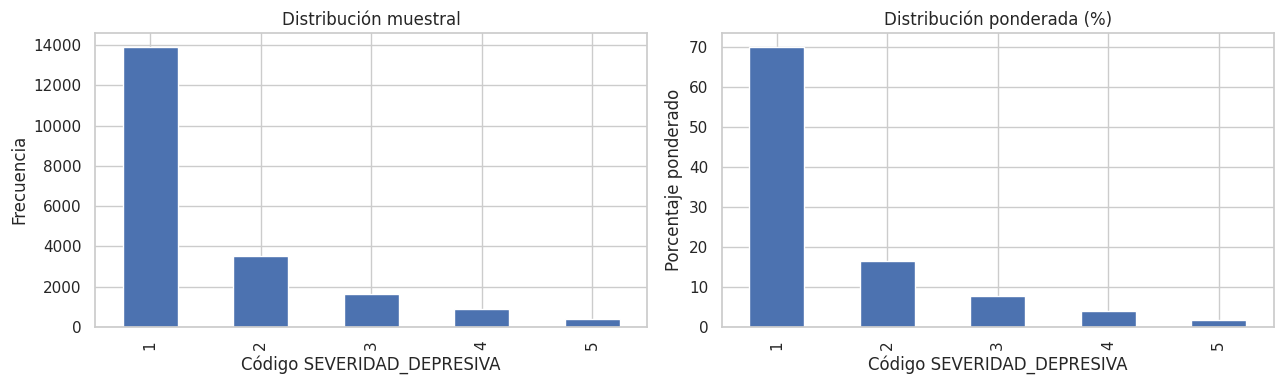

In [ ]:
# Frecuencias no ponderadas
freq = df[target].value_counts().sort_index()
pct = df[target].value_counts(normalize=True).sort_index() * 100

# Distribución ponderada
weighted = df.groupby(target)[weight_col].sum().sort_index()
weighted_pct = weighted / weighted.sum() * 100

target_distribution = pd.DataFrame({
    "frecuencia_muestral": freq,
    "porcentaje_muestral": pct,
    "total_ponderado": weighted,
    "porcentaje_ponderado": weighted_pct
}).round(2)

display(target_distribution)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
freq.plot(kind="bar", ax=axes[0], title="Distribución muestral")
weighted_pct.plot(kind="bar", ax=axes[1], title="Distribución ponderada (%)")
axes[0].set_xlabel("Código SEVERIDAD_DEPRESIVA")
axes[1].set_xlabel("Código SEVERIDAD_DEPRESIVA")
axes[0].set_ylabel("Frecuencia")
axes[1].set_ylabel("Porcentaje ponderado")
plt.tight_layout()
plt.show()

### 7.2. Variables numéricas y categóricas

La edad se describe mediante estadísticos básicos y un histograma de frecuencias. Para las variables categóricas se presentan las frecuencias y los porcentajes ponderados mediante `FACTORADULTO`. La interpretación de las categorías se realiza de acuerdo con la codificación recogida en el cuestionario.

,count,mean,std,min,25%,50%,75%,max
EDADa,20333.0,54.361826,19.102086,15.0,40.0,55.0,69.0,102.0


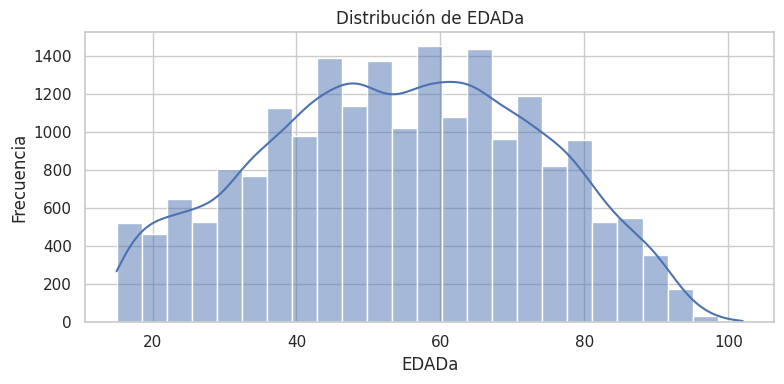


SEXOa


,total_ponderado,porcentaje_ponderado
SEXOa,,
2,20866919.7,51.39
1,19737459.7,48.61



NIVEST


,total_ponderado,porcentaje_ponderado
NIVEST,,
9,9647916.3,23.76
5,9344061.5,23.01
6,6009026.0,14.80
4,5967563.7,14.70
7,3674829.7,9.05
8,3568124.7,8.79
NaN,2161009.1,5.32
2,231848.4,0.57



A4


,total_ponderado,porcentaje_ponderado
A4,,
1,20744520.8,51.09
3,17452315.4,42.98
2,1420289.3,3.50
NaN,987253.9,2.43


... (36 outputs left out)


C5b_8


,total_ponderado,porcentaje_ponderado
C5b_8,,
3,31931208.0,78.64
1,7798908.9,19.21
2,580320.5,1.43
NaN,293941.9,0.72



C5b_12


,total_ponderado,porcentaje_ponderado
C5b_12,,
3,37327262.9,91.93
1,2865025.8,7.06
NaN,275145.4,0.68
2,136945.3,0.34


In [ ]:
display(df[numeric_features].describe().T)

for col in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col].dropna(), bins=25, kde=True)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

for col in categorical_features:
    tab = df.groupby(col, dropna=False)[weight_col].sum().sort_values(ascending=False)
    tab_pct = (tab / tab.sum() * 100).round(2)
    print(f"\n{col}")
    display(pd.DataFrame({"total_ponderado": tab.round(1), "porcentaje_ponderado": tab_pct}))

## 8. Análisis exploratorio bivariante

Se comparará la distribución de la variable objetivo entre categorías de los predictores. Para variables categóricas se calcularán porcentajes ponderados dentro de cada categoría explicativa. Estos resultados describen asociaciones y no deben interpretarse como relaciones causales.

Distribución ponderada de SEVERIDAD_DEPRESIVA según SEXOa (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
SEXOa,,,,,
1,75.6,14.0,6.2,3.0,1.1
2,64.9,18.7,9.1,5.1,2.2


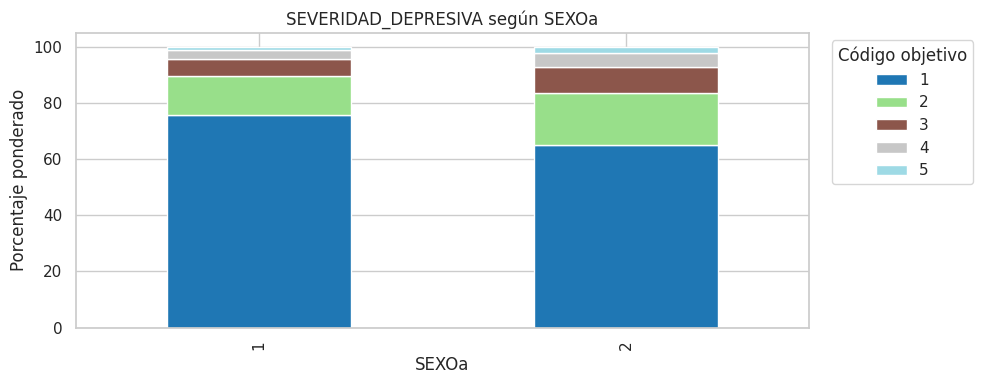

Distribución ponderada de SEVERIDAD_DEPRESIVA según NIVEST (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
NIVEST,,,,,
2,48.9,23.3,10.0,12.0,5.8
4,65.2,17.2,10.3,5.2,2.2
5,73.1,14.7,6.9,3.6,1.7
6,73.1,15.8,6.8,3.2,1.0
7,70.7,16.4,6.4,4.9,1.6
8,71.3,15.4,7.6,3.6,1.9
9,72.3,17.3,6.4,2.9,1.2


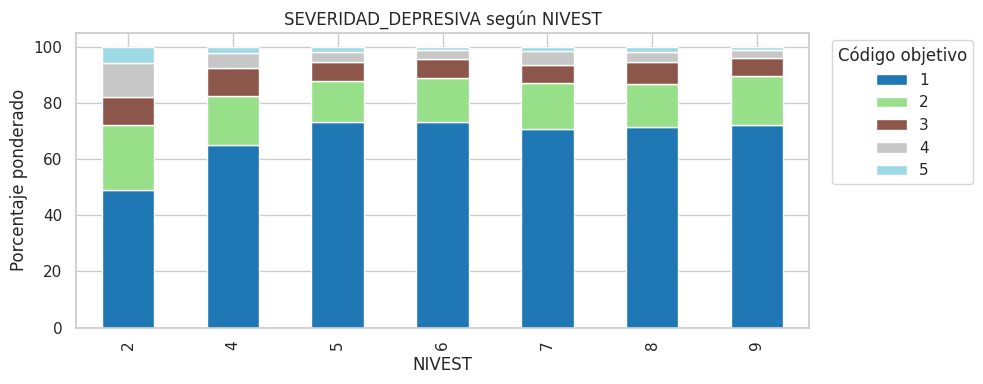

Distribución ponderada de SEVERIDAD_DEPRESIVA según C1 (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
C1,,,,,
1,90.9,6.6,1.8,0.6,0.1
2,76.0,15.0,5.8,2.7,0.4
3,50.2,27.2,13.6,6.8,2.1
4,24.2,27.1,22.4,15.9,10.4
5,15.2,15.4,21.5,18.5,29.5


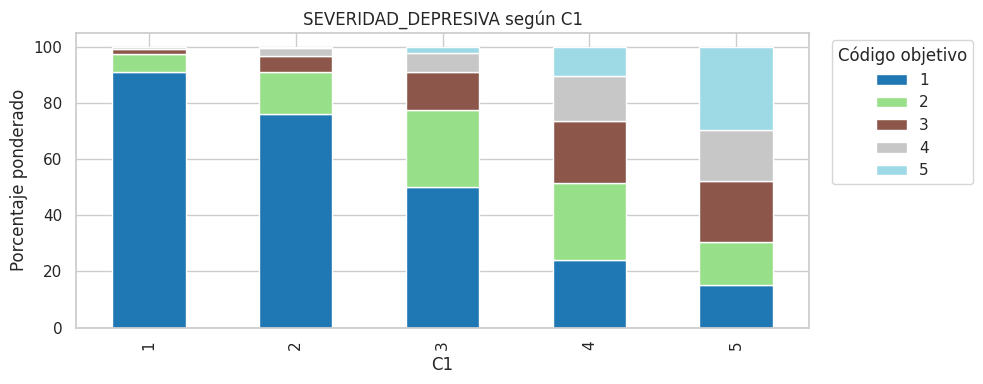

Distribución ponderada de SEVERIDAD_DEPRESIVA según C2 (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
C2,,,,,
1,60.2,21.0,10.4,5.8,2.7
2,84.2,10.0,3.9,1.6,0.3


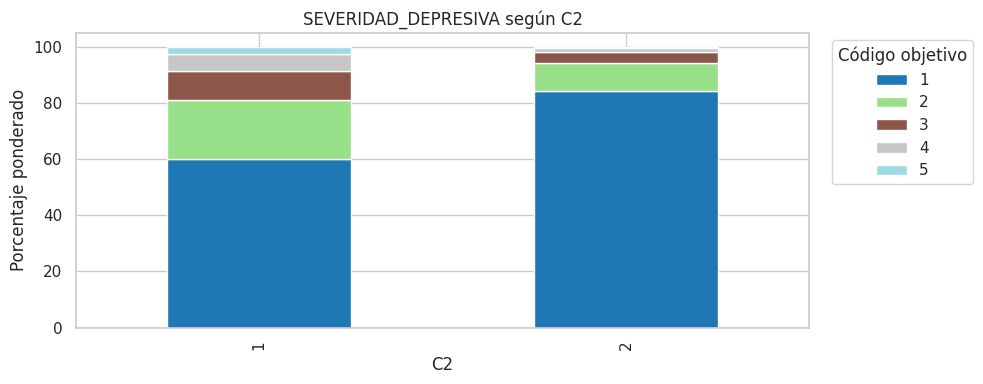

Distribución ponderada de SEVERIDAD_DEPRESIVA según C3a (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
C3a,,,,,
1,21.2,22.9,22.8,18.6,14.5
2,49.0,27.6,13.0,7.2,3.2
3,79.5,12.7,5.1,2.2,0.4


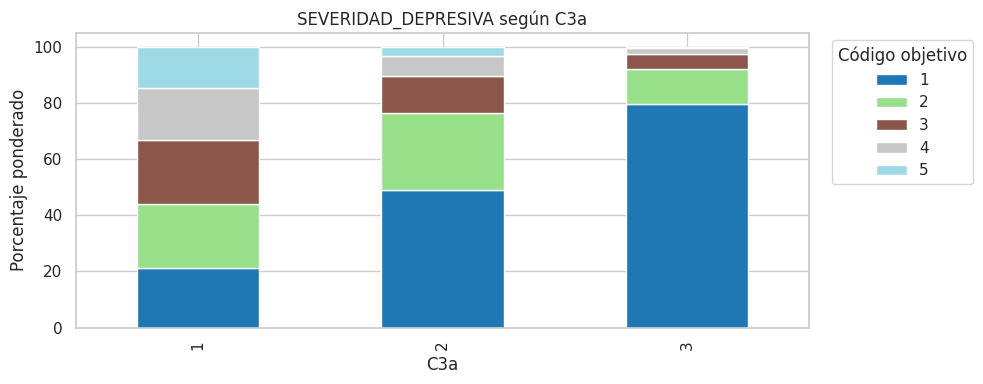

Distribución ponderada de SEVERIDAD_DEPRESIVA según O2 (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
O2,,,,,
1,63.6,18.2,9.7,5.3,3.2
2,68.9,17.0,8.7,4.3,1.1
3,77.4,13.9,5.0,2.8,0.9
4,79.4,14.0,4.0,2.0,0.6


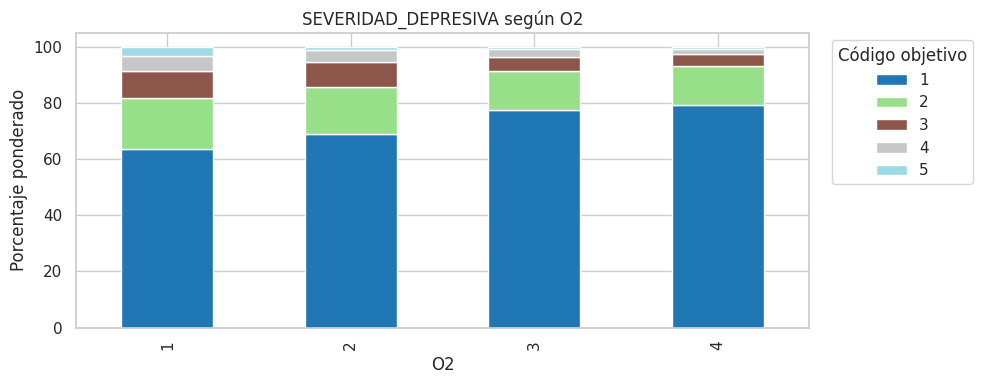

Distribución ponderada de SEVERIDAD_DEPRESIVA según IMC (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
IMC,,,,,
1,65.8,16.9,6.7,8.3,2.2
2,72.6,15.7,6.7,3.6,1.4
3,71.4,15.4,8.0,3.8,1.5
4,61.7,20.4,10.2,5.3,2.5


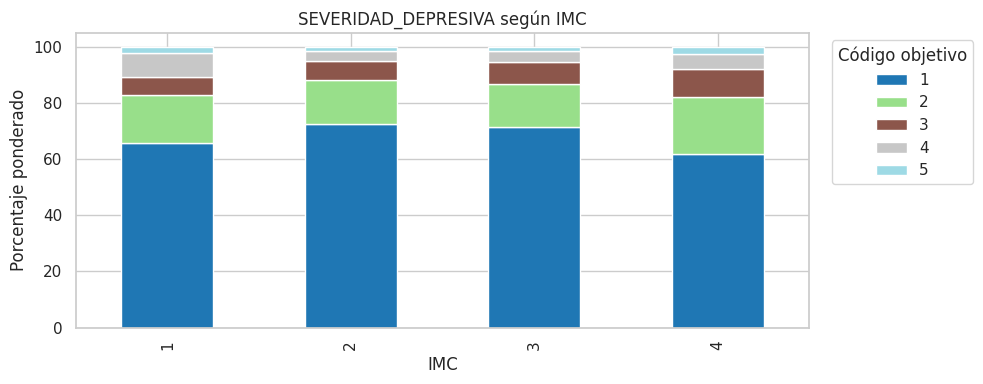

Distribución ponderada de SEVERIDAD_DEPRESIVA según R1 (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
R1,,,,,
1,76.5,14.2,6.0,2.6,0.7
2,73.0,14.3,8.5,3.6,0.7
3,68.1,19.0,8.6,3.3,1.0
4,74.3,16.6,5.2,2.6,1.3
5,74.0,14.7,7.0,3.4,0.8
6,73.0,15.0,7.3,3.6,1.2
7,72.3,16.4,6.3,3.3,1.6
8,55.9,20.4,12.8,7.9,2.9
9,68.0,16.2,8.5,4.6,2.7


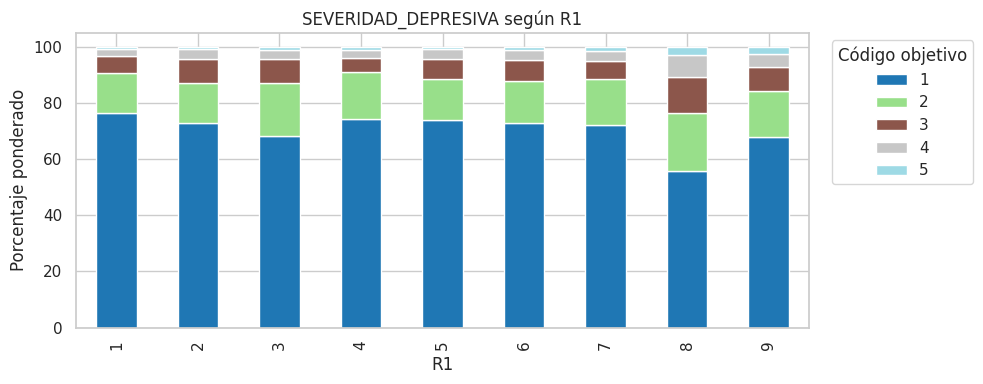

Distribución ponderada de SEVERIDAD_DEPRESIVA según S1 (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
S1,,,,,
1,50.9,20.7,16.4,7.7,4.4
2,62.6,19.0,9.2,6.1,3.2
3,70.8,16.7,7.5,3.5,1.6
4,74.0,14.7,7.0,3.4,0.9


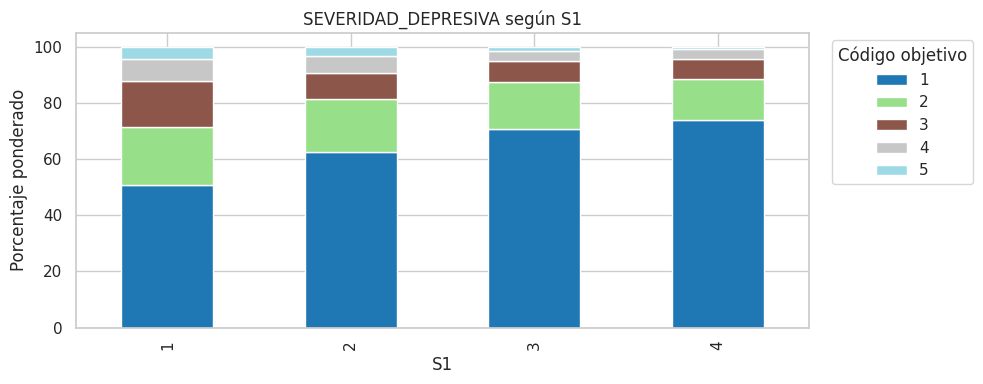

Distribución ponderada de SEVERIDAD_DEPRESIVA según S2 (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
S2,,,,,
1,75.7,15.2,5.3,2.5,1.2
2,63.9,18.0,10.6,5.4,2.2
3,38.4,23.9,21.5,13.3,2.9
4,29.5,26.8,22.7,17.1,4.0
5,38.3,13.8,21.4,16.1,10.3


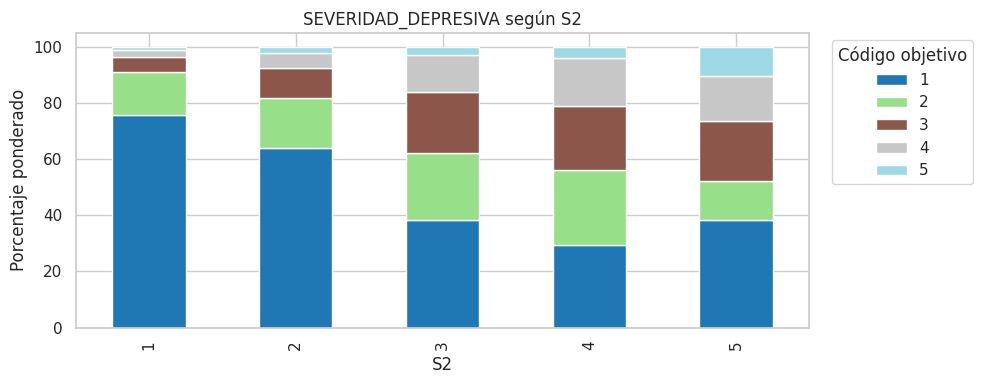

Distribución ponderada de SEVERIDAD_DEPRESIVA según S3 (%)


SEVERIDAD_DEPRESIVA,1,2,3,4,5
S3,,,,,
1,73.9,15.5,6.2,3.2,1.2
2,72.0,15.1,7.8,3.9,1.2
3,67.2,18.7,8.1,4.1,1.8
4,64.5,18.5,9.2,4.8,3.0
5,54.6,19.2,11.5,9.2,5.6


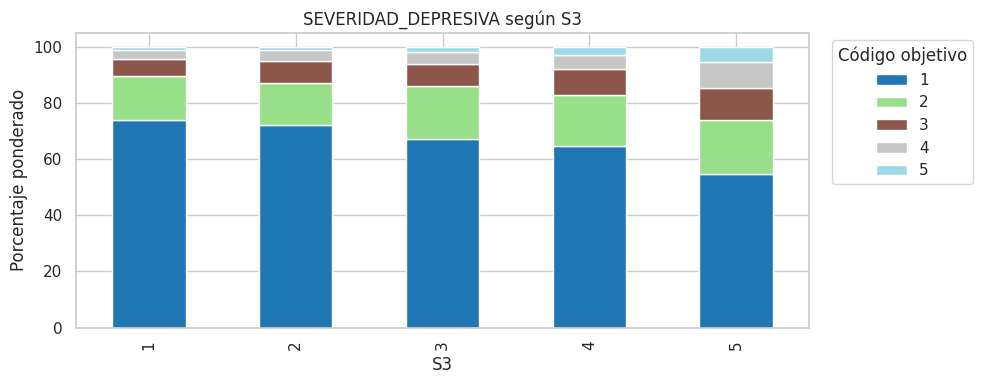

In [ ]:
def weighted_crosstab_percent(data, predictor, outcome=target, weight=weight_col):
    tab = data.pivot_table(
        index=predictor,
        columns=outcome,
        values=weight,
        aggfunc="sum",
        fill_value=0
    )
    return tab.div(tab.sum(axis=1), axis=0) * 100

for col in ["SEXOa", "NIVEST", "C1", "C2", "C3a", "O2", "IMC", "R1", "S1", "S2", "S3"]:
    print(f"Distribución ponderada de {target} según {col} (%)")
    display(weighted_crosstab_percent(df, col).round(1))

    ax = weighted_crosstab_percent(df, col).plot(
        kind="bar", stacked=True, figsize=(10, 4), colormap="tab20"
    )
    ax.set_title(f"{target} según {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Porcentaje ponderado")
    ax.legend(title="Código objetivo", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## 9. Preparación para la modelización

Se conserva la variable objetivo en cinco categorías. La partición se estratifica para mantener aproximadamente la distribución de clases en entrenamiento y prueba.

Las transformaciones se ajustan exclusivamente con el conjunto de entrenamiento dentro de los pipelines:
- Variables numéricas: imputación por mediana y estandarización para regresión logística.
- Variables categóricas: imputación por categoría más frecuente y codificación One-Hot.
- Random Forest utiliza la misma codificación para garantizar una comparación sobre los mismos predictores.

El factor `FACTORADULTO` se utiliza como peso de observación en el ajuste y en las métricas ponderadas. Para el entrenamiento se normalizan los pesos por su media en el conjunto de entrenamiento, manteniendo las proporciones relativas y evitando que la escala del factor altere innecesariamente la regularización.

In [ ]:
X = df[numeric_features + categorical_features].copy()
y = df[target].copy()
sample_weight = df[weight_col].copy()

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, sample_weight,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

w_train_fit = w_train / w_train.mean()

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("\nDistribución objetivo entrenamiento:")
display(y_train.value_counts(normalize=True).sort_index().mul(100).round(2))
print("\nDistribución objetivo prueba:")
display(y_test.value_counts(normalize=True).sort_index().mul(100).round(2))

Entrenamiento: (16266, 24)
Prueba: (4067, 24)

Distribución objetivo entrenamiento:


,proportion
SEVERIDAD_DEPRESIVA,
1,68.44
2,17.25
3,8.10
4,4.32
5,1.89



Distribución objetivo prueba:


,proportion
SEVERIDAD_DEPRESIVA,
1,68.43
2,17.26
3,8.11
4,4.33
5,1.87


## 10. Construcción de los pipelines

Se crean transformadores separados para variables numéricas y categóricas. El uso de pipelines evita que la imputación, la estandarización o la codificación utilicen información del conjunto de prueba.

In [ ]:
numeric_transformer_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_lr = ColumnTransformer(transformers=[
    ("num", numeric_transformer_lr, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

preprocessor_rf = ColumnTransformer(transformers=[
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

## 11. Regresión logística multinomial

La regresión logística multinomial se utiliza como modelo de referencia. Se mantienen las cinco clases originales. El modelo devuelve probabilidades para cada categoría y permite establecer una referencia interpretable frente a Random Forest.

In [ ]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor_lr),
    ("model", LogisticRegression(
        solver="lbfgs",
        max_iter=3000,
        C=1.0,
        random_state=SEED
    ))
])


## 12. Random Forest

Random Forest combina múltiples árboles de decisión y permite identificar relaciones no lineales e interacciones entre las variables explicativas. En este trabajo se utiliza una configuración inicial del algoritmo, definida mediante sus principales hiperparámetros, para evaluar su capacidad de clasificación y comparar sus resultados con los de la regresión logística.

In [ ]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("model", RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=SEED,
        n_jobs=-1
    ))
])


## 13. Validación cruzada estratificada

Se aplica una validación cruzada estratificada de cinco particiones (*5-fold Stratified Cross-Validation*) sobre el conjunto de entrenamiento. En cada iteración, cuatro particiones se utilizan para ajustar el modelo y la restante para evaluar su rendimiento.

Los pipelines se ajustan de nuevo en cada iteración, incluyendo los procesos de imputación, codificación y escalado. También se utilizan los pesos `FACTORADULTO` durante el entrenamiento y en el cálculo de las métricas ponderadas.

Finalmente, se resumen los resultados de las cinco particiones mediante la media y la desviación típica de las métricas obtenidas. El conjunto de prueba se reserva para la evaluación final de los modelos.

In [ ]:
# Validación cruzada estratificada: solo se utiliza X_train, y_train y w_train
N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

def calculate_fold_metrics(y_true, y_pred, y_proba, weights, labels):
    """Calcula métricas comparables para una partición de validación."""
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "accuracy_ponderada": accuracy_score(y_true, y_pred, sample_weight=weights),
        "f1_macro_ponderado": f1_score(
            y_true, y_pred, average="macro", sample_weight=weights, zero_division=0
        )
    }
    try:
        metrics["roc_auc_ovr_macro_ponderado"] = roc_auc_score(
            y_true, y_proba, multi_class="ovr", average="macro",
            labels=labels, sample_weight=weights
        )
    except ValueError:
        metrics["roc_auc_ovr_macro_ponderado"] = np.nan
    return metrics

def run_stratified_cv(model, model_name):
    fold_results = []
    labels = np.sort(y_train.unique())

    for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train, y_train), start=1):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_valid = X_train.iloc[valid_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_valid = y_train.iloc[valid_idx]
        w_fold_train = w_train.iloc[train_idx]
        w_fold_valid = w_train.iloc[valid_idx]

        # Normalización de los pesos solo con el subconjunto usado para entrenar.
        w_fold_fit = w_fold_train / w_fold_train.mean()

        fold_model = clone(model)
        fold_model.fit(
            X_fold_train, y_fold_train,
            model__sample_weight=w_fold_fit
        )

        fold_pred = fold_model.predict(X_fold_valid)
        fold_proba = fold_model.predict_proba(X_fold_valid)
        fold_metrics = calculate_fold_metrics(
            y_fold_valid, fold_pred, fold_proba, w_fold_valid, labels
        )
        fold_metrics["modelo"] = model_name
        fold_metrics["particion"] = fold
        fold_results.append(fold_metrics)

    return pd.DataFrame(fold_results)

cv_lr = run_stratified_cv(logistic_model, "Regresión logística")
cv_rf = run_stratified_cv(rf_model, "Random Forest")
cv_results = pd.concat([cv_lr, cv_rf], ignore_index=True)

metric_columns = [
    "accuracy", "balanced_accuracy", "precision_macro", "recall_macro",
    "f1_macro", "f1_weighted", "accuracy_ponderada",
    "f1_macro_ponderado", "roc_auc_ovr_macro_ponderado"
]
cv_summary = cv_results.groupby("modelo")[metric_columns].agg(["mean", "std"])

print(f"Validación cruzada completada: {N_SPLITS} particiones estratificadas.")
display(cv_results.round(4))
display(cv_summary.round(4))

Validación cruzada completada: 5 particiones estratificadas.


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy_ponderada,f1_macro_ponderado,roc_auc_ovr_macro_ponderado,modelo,particion
0,0.6911,0.3094,0.4062,0.3094,0.3288,0.6303,0.7059,0.3455,0.8083,Regresión logística,1
1,0.6917,0.2797,0.3422,0.2797,0.2898,0.6341,0.7094,0.2801,0.7840,Regresión logística,2
2,0.6898,0.2731,0.3388,0.2731,0.2824,0.6285,0.7039,0.2847,0.8009,Regresión logística,3
3,0.6920,0.2960,0.3569,0.2960,0.3076,0.6353,0.7036,0.3090,0.8080,Regresión logística,4
4,0.7000,0.3103,0.4190,0.3103,0.3331,0.6407,0.7156,0.3106,0.8192,Regresión logística,5
5,0.6930,0.2689,0.3786,0.2689,0.2780,0.6069,0.7063,0.2927,0.8178,Random Forest,1
6,0.6975,0.2434,0.3366,0.2434,0.2403,0.6054,0.7150,0.2315,0.7988,Random Forest,2
7,0.6997,0.2578,0.4737,0.2578,0.2670,0.6141,0.7138,0.2664,0.8197,Random Forest,3
8,0.6926,0.2615,0.3530,0.2615,0.2667,0.6075,0.7047,0.2702,0.8166,Random Forest,4
9,0.6972,0.2652,0.4604,0.2652,0.2781,0.6118,0.7139,0.2668,0.8221,Random Forest,5


accuracy         balanced_accuracy          \
                        mean     std              mean     std   
modelo                                                           
Random Forest         0.6960  0.0031            0.2594  0.0098   
Regresión logística   0.6929  0.0040            0.2937  0.0170   

                    precision_macro         recall_macro         f1_macro  \
                               mean     std         mean     std     mean   
modelo                                                                      
Random Forest                0.4005  0.0628       0.2594  0.0098   0.2660   
Regresión logística          0.3726  0.0374       0.2937  0.0170   0.3083   

                            f1_weighted         accuracy_ponderada          \
                        std        mean     std               mean     std   
modelo                                                                       
Random Forest        0.0154      0.6091  0.0036             0.7107  0.0048   
Regresión logística  0.0226      0.6338  0.0047             0.7077  0.0050   

                    f1_macro_ponderado         roc_auc_ovr_macro_ponderado  \
                                  mean     std                        mean   
modelo                                                                       
Random Forest                   0.2655  0.0219                      0.8150   
Regresión logística             0.3060  0.0261                      0.8041   

                             
                        std  
modelo                       
Random Forest        0.0093  
Regresión logística  0.0130

### Ajuste final y evaluación en el conjunto de prueba

Una vez estimada la variabilidad mediante validación cruzada, cada pipeline se vuelve a ajustar utilizando todas las observaciones del conjunto de entrenamiento (80 %). A continuación, se generan las predicciones sobre el conjunto de prueba reservado (20 %). Este conjunto se utiliza una sola vez para la evaluación final y no interviene en la validación cruzada ni en la selección de la configuración.

In [ ]:
# Reajuste de los modelos con todo el conjunto de entrenamiento
logistic_model.fit(
    X_train, y_train,
    model__sample_weight=w_train_fit
)

rf_model.fit(
    X_train, y_train,
    model__sample_weight=w_train_fit
)

# Predicciones finales sobre el conjunto de prueba independiente
pred_lr = logistic_model.predict(X_test)
proba_lr = logistic_model.predict_proba(X_test)
pred_rf = rf_model.predict(X_test)
proba_rf = rf_model.predict_proba(X_test)

print("Modelos reajustados con todo el conjunto de entrenamiento.")

Modelos reajustados con todo el conjunto de entrenamiento.


## 14. Evaluación final de los modelos

Se presentan métricas sin ponderar y ponderadas. La exactitud no se utiliza como único criterio. Se presta especial atención a la sensibilidad por clase y a F1 macro, que otorga el mismo peso a cada categoría.

ROC-AUC se calcula en esquema One-vs-Rest si están presentes todas las clases en el conjunto de prueba.

In [ ]:
classes = np.sort(y.unique())

def evaluate_model(name, y_true, y_pred, y_proba, weights):
    results = {
        "modelo": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "accuracy_ponderada": accuracy_score(y_true, y_pred, sample_weight=weights),
        "f1_macro_ponderado": f1_score(
            y_true, y_pred, average="macro", sample_weight=weights, zero_division=0
        )
    }

    try:
        results["roc_auc_ovr_macro"] = roc_auc_score(
            y_true, y_proba, multi_class="ovr", average="macro",
            labels=classes, sample_weight=weights
        )
    except Exception:
        results["roc_auc_ovr_macro"] = np.nan

    print(f"\n{name} — informe de clasificación sin ponderar")
    print(classification_report(y_true, y_pred, zero_division=0))

    print(f"{name} — informe ponderado")
    print(classification_report(
        y_true, y_pred, sample_weight=weights, zero_division=0
    ))

    return results

results = []
results.append(evaluate_model("Regresión logística", y_test, pred_lr, proba_lr, w_test))
results.append(evaluate_model("Random Forest", y_test, pred_rf, proba_rf, w_test))

results_df = pd.DataFrame(results).set_index("modelo")
display(results_df.round(4))


Regresión logística — informe de clasificación sin ponderar
              precision    recall  f1-score   support

           1       0.76      0.95      0.84      2783
           2       0.34      0.14      0.20       702
           3       0.28      0.14      0.19       330
           4       0.25      0.09      0.13       176
           5       0.28      0.17      0.21        76

    accuracy                           0.69      4067
   macro avg       0.38      0.30      0.31      4067
weighted avg       0.61      0.69      0.63      4067

Regresión logística — informe ponderado
              precision    recall  f1-score   support

           1       0.76      0.96      0.85 5607419.564000012
           2       0.32      0.11      0.16 1339856.7
           3       0.29      0.16      0.20 621306.0299999998
           4       0.28      0.07      0.12 331455.8309999998
           5       0.28      0.15      0.20 130562.56200000002

    accuracy                           0.71 8030600

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy_ponderada,f1_macro_ponderado,roc_auc_ovr_macro
modelo,,,,,,,,,
Regresión logística,0.6934,0.2977,0.3811,0.2977,0.3133,0.6348,0.7073,0.3059,0.7994
Random Forest,0.6981,0.2586,0.3969,0.2586,0.2647,0.6163,0.7090,0.2439,0.8106


### 14.1. Matrices de confusión

La matriz permite identificar qué categorías se confunden con mayor frecuencia. Se presenta una matriz de frecuencias y otra normalizada por fila.

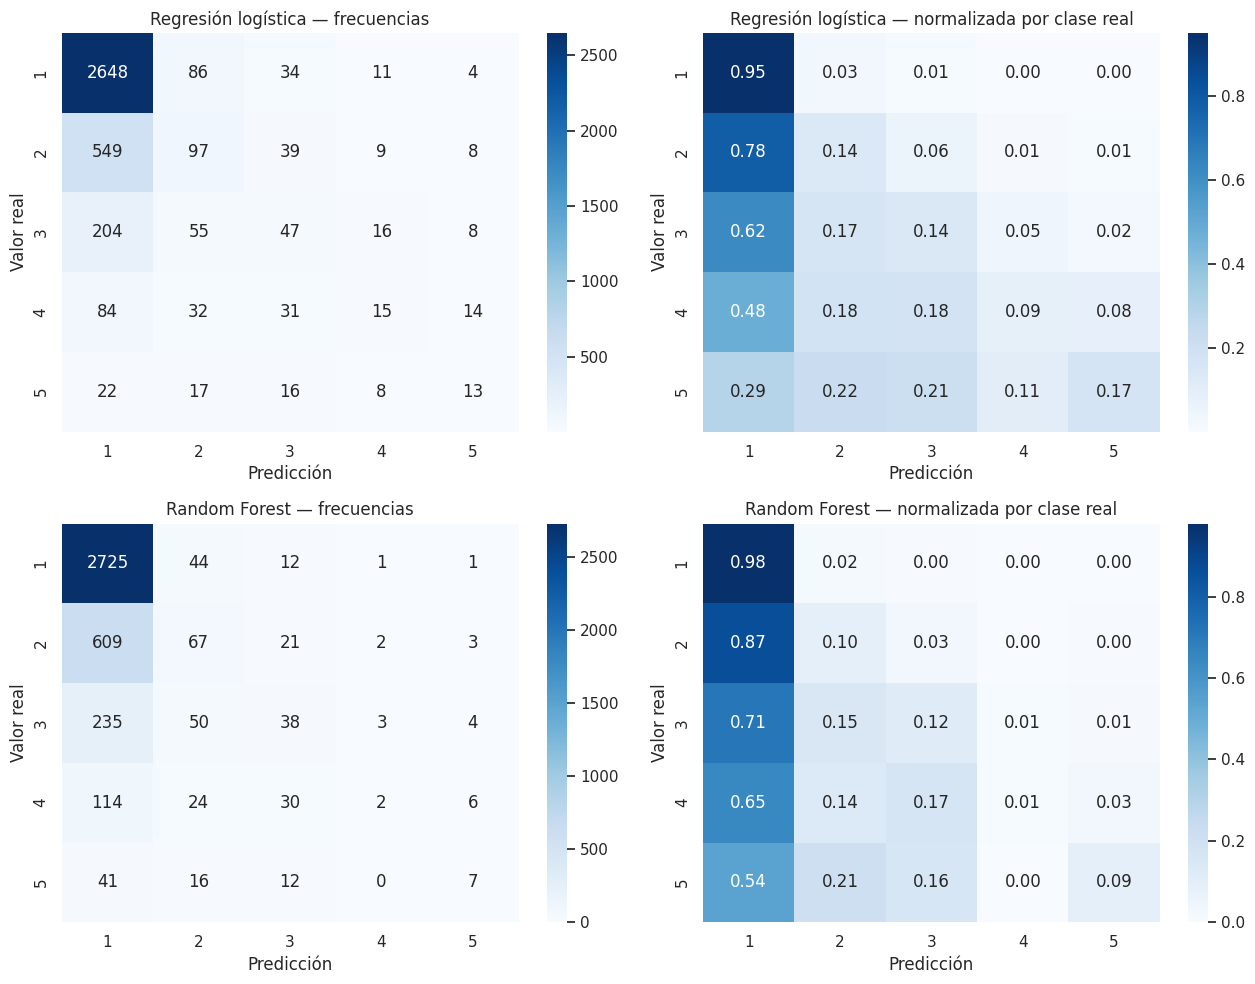

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, (name, pred) in enumerate([
    ("Regresión logística", pred_lr),
    ("Random Forest", pred_rf)
]):
    cm = confusion_matrix(y_test, pred, labels=classes)
    cm_norm = confusion_matrix(y_test, pred, labels=classes, normalize="true")

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes, ax=axes[row, 0])
    axes[row, 0].set_title(f"{name} — frecuencias")
    axes[row, 0].set_xlabel("Predicción")
    axes[row, 0].set_ylabel("Valor real")

    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=classes, yticklabels=classes, ax=axes[row, 1])
    axes[row, 1].set_title(f"{name} — normalizada por clase real")
    axes[row, 1].set_xlabel("Predicción")
    axes[row, 1].set_ylabel("Valor real")

plt.tight_layout()
plt.show()

## 15. Importancia de variables mediante permutación

La importancia por permutación mide cuánto empeora una métrica cuando se desordena una variable. Se calcula sobre el conjunto de prueba y con F1 macro. La importancia representa contribución predictiva en este modelo y no implica causalidad.

,variable,importancia_media,desviacion
8,C1,0.067768,0.005621
10,C3a,0.062294,0.006646
6,CCAA,0.021973,0.003235
21,C5b_7,0.019484,0.001475
12,O2,0.019275,0.001343
16,S2,0.018043,0.001523
9,C2,0.017851,0.003708
11,C4,0.014540,0.001872
14,R1,0.007971,0.002419
22,C5b_8,0.006931,0.003013


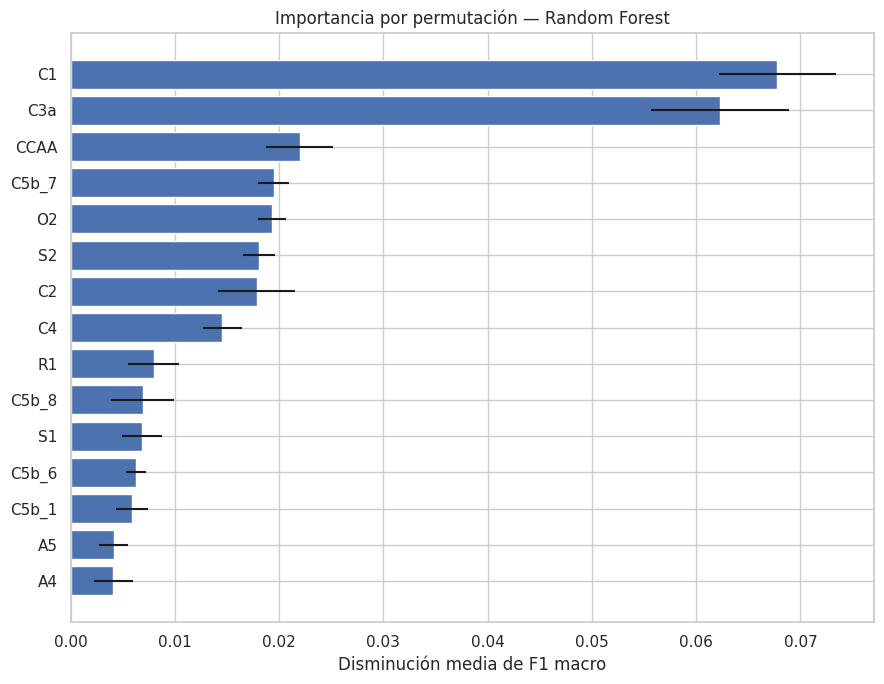

In [ ]:
perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=SEED,
    scoring="f1_macro",
    n_jobs=-1
)

importance = pd.DataFrame({
    "variable": X_test.columns,
    "importancia_media": perm.importances_mean,
    "desviacion": perm.importances_std
}).sort_values("importancia_media", ascending=False)

display(importance.head(20))

plt.figure(figsize=(9, 7))
top_imp = importance.head(15).sort_values("importancia_media")
plt.barh(top_imp["variable"], top_imp["importancia_media"], xerr=top_imp["desviacion"])
plt.xlabel("Disminución media de F1 macro")
plt.title("Importancia por permutación — Random Forest")
plt.tight_layout()
plt.show()

## 16. Comparación y exportación de resultados

La selección del modelo no debe basarse en una sola métrica. Se revisarán especialmente F1 macro, sensibilidad por categoría, matrices de confusión y ROC-AUC cuando sea calculable. Se conservarán las salidas para documentar el apartado 4.3.6 del TFM.

In [ ]:
# Tabla comparativa de métricas
display(results_df.round(4))

# Guardar tablas principales
target_distribution.to_csv("distribucion_variable_objetivo.csv", encoding="utf-8-sig")
results_df.to_csv("comparacion_modelos.csv", encoding="utf-8-sig")
cv_results.to_csv("validacion_cruzada_resultados_por_particion.csv", index=False, encoding="utf-8-sig")
cv_summary.to_csv("validacion_cruzada_resumen.csv", encoding="utf-8-sig")
importance.to_csv("importancia_variables_random_forest.csv", index=False, encoding="utf-8-sig")

print("Archivos CSV generados")

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy_ponderada,f1_macro_ponderado,roc_auc_ovr_macro
modelo,,,,,,,,,
Regresión logística,0.6934,0.2977,0.3811,0.2977,0.3133,0.6348,0.7073,0.3059,0.7994
Random Forest,0.6981,0.2586,0.3969,0.2586,0.2647,0.6163,0.7090,0.2439,0.8106


Archivos CSV generados
